In [1]:
import yfinance as yf  # load the library, nickname "yf"

# download daily SPY data since 2010 into a pandas table (DataFrame)
# auto_adjust=True corrects prices for dividends and splits,
# so a dividend day doesn't look like a fake price drop
spy = yf.download("SPY", start="2010-01-01", auto_adjust=True)

print(spy.shape)   # (number of rows, number of columns)
print(spy.head())  # first 5 rows

[*********************100%***********************]  1 of 1 completed

(4235, 5)
Price           Close       High        Low       Open     Volume
Ticker            SPY        SPY        SPY        SPY        SPY
Date                                                             
2010-01-04  84.368980  84.413646  83.014074  83.654305  118944600
2010-01-05  84.592316  84.629541  84.011642  84.316871  111579900
2010-01-06  84.651901  84.860348  84.443455  84.510453  116074400
2010-01-07  85.009186  85.113409  84.257286  84.495511  131091100
2010-01-08  85.292091  85.329316  84.614641  84.785862  126402800


In [2]:
# keep only the first header level (Close, High, ...) and drop "SPY"
spy.columns = spy.columns.droplevel(1)

print(spy.columns.tolist())  # list of column names
print(spy.isna().sum())      # missing values per column
print(spy.tail(3))           # last 3 rows

['Close', 'High', 'Low', 'Open', 'Volume']
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
Price            Close        High         Low        Open    Volume
Date                                                                
2026-10-30  755.719971  761.460022  750.359985  761.380005  77696500
2026-11-02  752.099976  763.859985  751.599976  759.450012  50804300
2026-11-03  754.200012  757.070007  752.409973  752.729980  27417620


In [3]:
print(spy.columns.tolist())  # what are the column names right now?

['Close', 'High', 'Low', 'Open', 'Volume']


In [4]:
print(spy.isna().sum())  # for each column: how many empty cells (isna = "is missing?")
print(spy.tail(3))       # last 3 rows: the most recent trading days
print(spy.index.is_monotonic_increasing)  # True if the dates are in order, oldest to newest

Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
Price            Close        High         Low        Open    Volume
Date                                                                
2026-10-30  755.719971  761.460022  750.359985  761.380005  77696500
2026-11-02  752.099976  763.859985  751.599976  759.450012  50804300
2026-11-03  754.200012  757.070007  752.409973  752.729980  27417620
True


In [5]:
import os  # tools to work with folders

os.makedirs("data", exist_ok=True)  # create the "data" folder if it doesn't exist yet
spy.to_csv("data/spy.csv")          # save the table as a CSV text file
print(os.path.getsize("data/spy.csv"), "bytes saved")

401118 bytes saved


In [6]:
import pandas as pd  # table library, nickname "pd"

# load the saved CSV; index_col makes "Date" the row labels,
# parse_dates turns the text into real dates
spy = pd.read_csv("data/spy.csv", index_col="Date", parse_dates=True)

# daily return = (today's close - yesterday's close) / yesterday's close
spy["ret"] = spy["Close"].pct_change()

print(spy[["Close", "ret"]].head())

                Close       ret
Date                           
2010-01-04  84.368980       NaN
2010-01-05  84.592316  0.002647
2010-01-06  84.651901  0.000704
2010-01-07  85.009186  0.004221
2010-01-08  85.292091  0.003328


In [7]:
daily = [0.01, -0.01, 0.01, -0.01]   # a calm stock: moves 1% each day
wild  = [0.05, -0.05, 0.05, -0.05]   # a wild stock: moves 5% each day

# both average 0, but the spread is very different
print(pd.Series(daily).std())  # about 0.0115
print(pd.Series(wild).std())   # about 0.0577 -> 5x more volatile

0.011547005383792516
0.05773502691896258


In [8]:
print(spy["ret"].mean())  # the average daily return
print(spy["ret"].std())   # the daily volatility (NaN in row 1 is skipped automatically)

0.0005751017926485656
0.010722112622241995


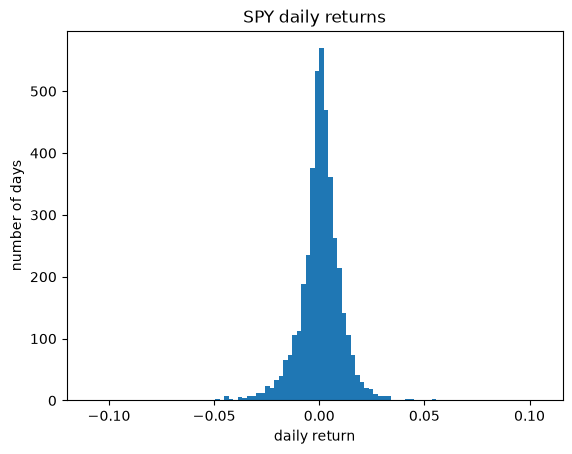

In [9]:
import matplotlib.pyplot as plt  # plotting library, nickname "plt"

# histogram: how many days had each return size
# bins=100 splits the range into 100 bars; dropna() removes the NaN in row 1
plt.hist(spy["ret"].dropna(), bins=100)
plt.title("SPY daily returns")
plt.xlabel("daily return")
plt.ylabel("number of days")
plt.show()  # draw it

In [10]:
# the 5 worst days (most negative returns), from the smallest value up
print(spy["ret"].nsmallest(5))

# the 5 best days
print(spy["ret"].nlargest(5))

Date
2020-03-16   -0.109424
2020-03-12   -0.095677
2020-03-09   -0.078095
2011-08-08   -0.065123
2025-04-04   -0.058543
Name: ret, dtype: float64
Date
2025-04-09    0.105019
2020-03-24    0.090603
2020-03-13    0.085486
2020-04-06    0.067166
2020-03-26    0.058390
Name: ret, dtype: float64


In [11]:
# a calm stretch followed by a stormy one (made-up daily returns)
returns = [0.001, -0.002, 0.001, 0.002, -0.001,   # calm days
           0.03, -0.04, 0.05, -0.03, 0.04]        # stormy days

import pandas as pd
r = pd.Series(returns)

# std of each 5-day window: small, then big -> volatility comes in clumps
print(r[:5].std())   # about 0.0016
print(r[5:].std())   # about 0.0422

0.0016431676725154984
0.04183300132670378


<Axes: title={'center': 'SPY 21-day rolling volatility'}, xlabel='Date'>

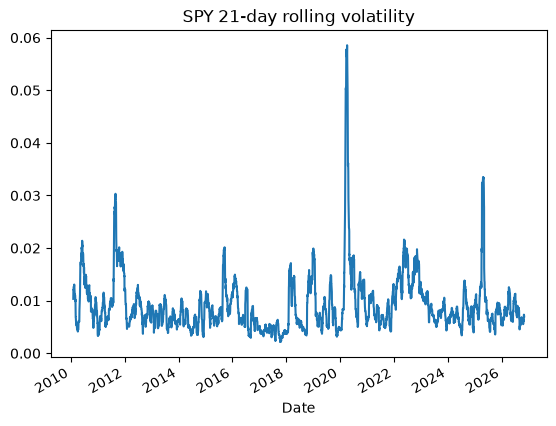

In [12]:
# rolling(21) = for each day, look at that day and the previous 20 trading days
# (about one month) and take the std of those returns
spy["vol_21"] = spy["ret"].rolling(21).std()

spy["vol_21"].plot(title="SPY 21-day rolling volatility")  # draw a line chart

In [13]:

# create the three rolling volatilities (each is a new column)
spy["vol_5"] = spy["ret"].rolling(5).std()      # about one week
spy["vol_21"] = spy["ret"].rolling(21).std()    # about one month
spy["vol_126"] = spy["ret"].rolling(126).std()  # about six months
print(spy.columns.tolist())

['Close', 'High', 'Low', 'Open', 'Volume', 'ret', 'vol_21', 'vol_5', 'vol_126']


In [14]:
spy[["vol_5", "vol_21", "vol_126"]].groupby(spy.index.year).mean()

,vol_5,vol_21,vol_126
Date,,,
2010,0.009952,0.010805,0.012637
2011,0.012294,0.012731,0.011399
2012,0.007377,0.007971,0.010797
2013,0.006414,0.006941,0.007338
2014,0.006138,0.006559,0.006596
2015,0.008641,0.009169,0.008893
2016,0.007077,0.007804,0.009256
2017,0.003915,0.004237,0.004745
2018,0.008717,0.008997,0.008335


In [15]:
import numpy as np  # numeric library, nickname "np"

daily_vol = 0.0165           # 2020's daily volatility (1.65%)
annual_vol = daily_vol * np.sqrt(252)   # sqrt(252) is about 15.87
print(annual_vol)            # about 0.262 -> 26.2% per year

0.2619293797953945


In [16]:
import numpy as np
print(spy["ret"].std() * np.sqrt(252))   # the whole-period annualized volatility

0.17020826116607374


In [17]:
import pandas as pd  # pandas para la tabla

# tabla de juguete: 6 días con un "valor" cada uno
df = pd.DataFrame({"valor": [10, 20, 30, 40, 50, 60]})

# shift(-2): negativo = jala el valor de 2 filas DESPUÉS hacia la fila actual
df["futuro_2"] = df["valor"].shift(-2)

# shift(2): positivo = trae el valor de 2 filas ANTES (pasado)
df["pasado_2"] = df["valor"].shift(2)

print(df)  # las filas sin dato quedan como NaN (en las orillas)

   valor  futuro_2  pasado_2
0     10      30.0       NaN
1     20      40.0       NaN
2     30      50.0      10.0
3     40      60.0      20.0
4     50       NaN      30.0
5     60       NaN      40.0


In [18]:
# nueva columna = std de 5 días de ret, movida ___ filas hacia el futuro, anualizada
spy["target"] = spy["ret"].rolling(5).std().shift(-5) * np.sqrt(252)

In [19]:
print(spy["target"].tail(8))  # últimas 8 filas del target
print(spy["target"].isna().sum())  # cuántos NaN hay en total

Date
2026-10-23    0.162054
2026-10-26    0.145348
2026-10-27    0.135324
2026-10-28         NaN
2026-10-29         NaN
2026-10-30         NaN
2026-11-02         NaN
2026-11-03         NaN
Name: target, dtype: float64
5
